# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [2]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [3]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [4]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [6]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [7]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [8]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [9]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[0.0220]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.5685,  0.0334, -0.0883]], requires_grad=True)
Biais: Parameter containing:
tensor([-0.3483], requires_grad=True)


In [10]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie: tensor([[2.6175]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[0.5441, 0.2591, 0.4276]], requires_grad=True)
Biais: Parameter containing:
tensor([0.2722], requires_grad=True)


## 6. Construire un réseau avec `nn.Module`

In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [12]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


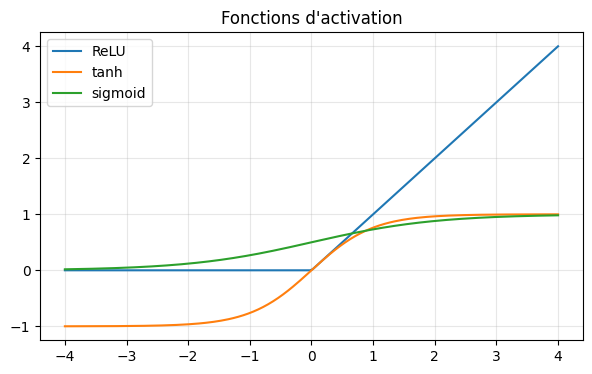

In [13]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [14]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [15]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [16]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [17]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 :
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=5.6006
epoch=100 loss=1.9305
epoch=200 loss=1.0357
epoch=300 loss=0.4972
epoch=400 loss=0.2076


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [18]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([0., 2., 0., 2., 2., 2., 2., 0., 0., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [19]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


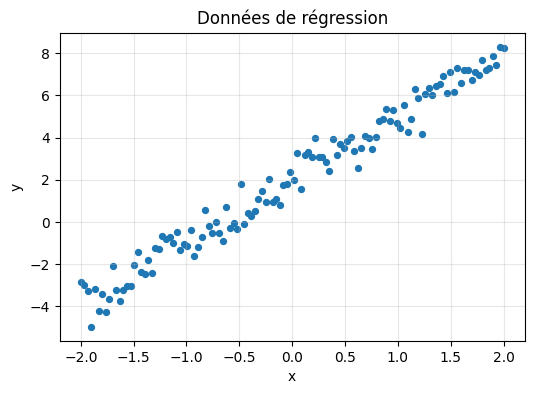

In [20]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [21]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [22]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


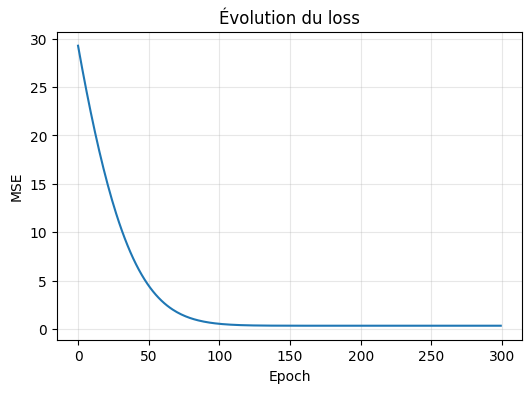

In [23]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


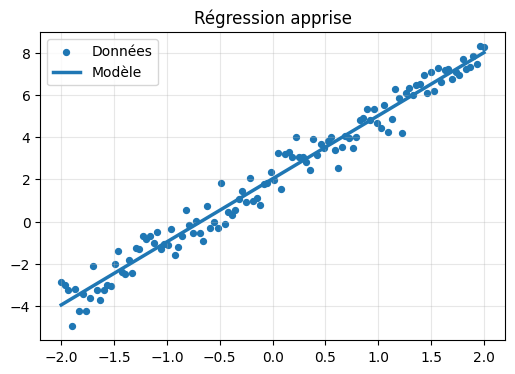

In [24]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


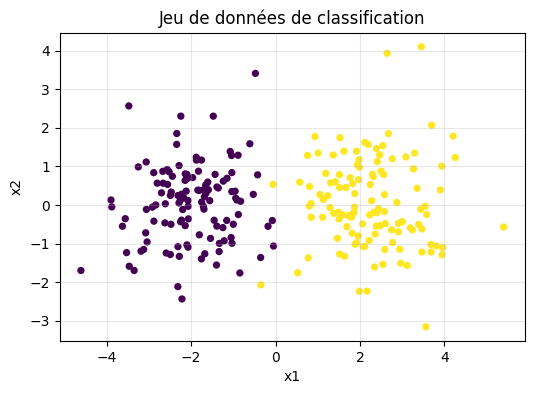

In [26]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [27]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [28]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943687913008034


In [29]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


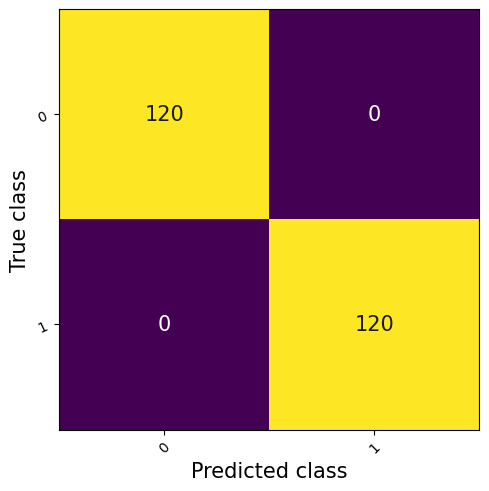

In [30]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


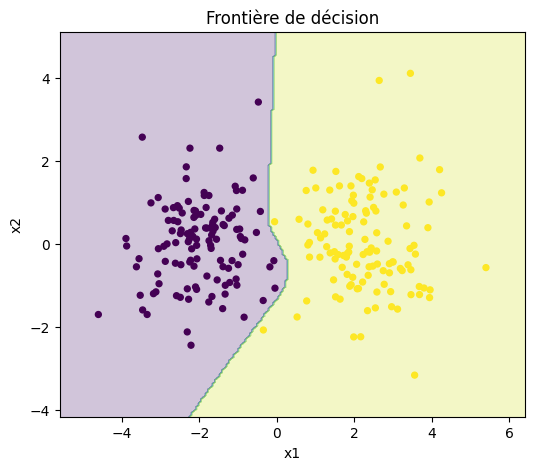

In [31]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [32]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [33]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


<string>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


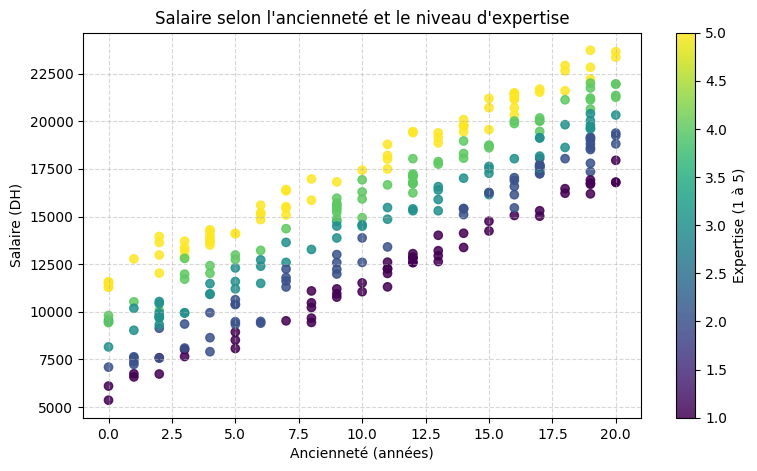

In [34]:
# 1. Dimensions de X et y
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# 2. Salaire moyen
salaire_moyen = y.mean().item()
print(f"Salaire moyen : {salaire_moyen:.2f} DH")

# 3. Nuage de points
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    X[:, 0].numpy(), 
    y.squeeze().numpy(), 
    c=X[:, 1].numpy(), 
    cmap="viridis", 
    alpha=0.85
)
cbar = plt.colorbar(scatter)
cbar.set_label("Expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire (DH)")
plt.title("Salaire selon l'ancienneté et le niveau d'expertise")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [35]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [36]:
# Deux variables d'entrée (ancienneté, expertise) et une sortie (salaire)
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )


Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


<string>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


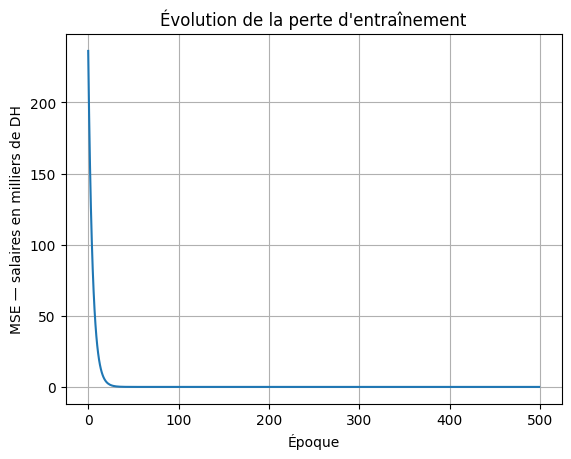

In [37]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [38]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Erreur absolue moyenne (MAE)
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")


Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [39]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    # Prédire et convertir de milliers de DH vers DH
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")


Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [40]:
# Retrouver les coefficients en unités d'origine
w = model.weight.data.squeeze()
b = model.bias.data.item()
mu = moyenne.squeeze()
sigma = ecart_type.squeeze()

# En dé-normalisant (facteur 1000 pour les DH) :
w_origine = 1000 * (w / sigma)
b_origine = 1000 * (b - torch.sum(w * mu / sigma).item())

print(f"w1 (ancienneté) : {w_origine[0].item():.2f} DH/an (valeur théorique : 600)")
print(f"w2 (expertise)  : {w_origine[1].item():.2f} DH/point (valeur théorique : 1500)")
print(f"b  (biais)      : {b_origine:.2f} DH (valeur théorique : 4000)")


w1 (ancienneté) : 592.66 DH/an (valeur théorique : 600)
w2 (expertise)  : 1490.75 DH/point (valeur théorique : 1500)
b  (biais)      : 4090.30 DH (valeur théorique : 4000)


### 💡 Réponses aux questions complémentaires (Exercice 1)

1. **À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?**
   - D'après la formule génératrice, chaque année d'ancienneté supplémentaire apporte en moyenne **600 DH** au salaire brut ($w_1 = 600$). Le modèle entraîné retrouve un coefficient $w_1$ très proche de cette valeur théorique (~600 DH/an).

2. **Pourquoi la perte ne devient-elle pas exactement nulle ?**
   - Les données contiennent un bruit gaussien aléatoire (`bruit = torch.randn(n, 1) * 500`). Même avec les paramètres optimaux parfaits ($w_1=600, w_2=1500, b=4000$), l'erreur résiduelle irréductible (variance du bruit $\sigma^2 = 500^2 = 250\,000\text{ DH}^2$, soit $\approx 0.25$ en milliers de DH$^2$) subsiste nécessairement.

3. **Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?**
   - **Non**, il s'agit d'une **extrapolation** hors du domaine d'apprentissage ($[0, 20]$ ans). En pratique, la relation linéaire peut ne plus être valable (effets de plafonnement des grilles salariales, changement de statut, départ à la retraite).

4. **Quel effet aurait une augmentation du bruit sur la précision ?**
   - Une hausse du bruit augmente la variance résiduelle, ce qui élève la MSE et la MAE sur les données de test, élargit les intervalles de confiance et rend l'estimation des coefficients $w_1, w_2, b$ plus instable (nécessitant plus de données pour converger).

**1. Préparation des données**

In [41]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

### 💡 Réponses aux questions (Préparation des données Iris)

1. **Que représentent les quatre colonnes de `X_train` ?**
   - **Colonne 0 :** Longueur des sépales (*sepal length* en cm).
   - **Colonne 1 :** Largeur des sépales (*sepal width* en cm).
   - **Colonne 2 :** Longueur des pétales (*petal length* en cm).
   - **Colonne 3 :** Largeur des pétales (*petal width* en cm).

2. **Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
   - Dans PyTorch, la fonction de coût `nn.CrossEntropyLoss` (et `nn.NLLLoss`) attend pour les étiquettes cibles des entiers 64 bits signés (`torch.long` ou `int64`). Ces étiquettes servent d'indices directs de classe ($0, 1, \dots, C-1$) pour indexer les tenseurs de log-probabilités.

3. **Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**
   - Pour éviter la **fuite d'information (*data leakage*)**. Les données de test simulent des données réelles inconnues en production. Le scaler doit donc apprendre la moyenne et l'écart-type uniquement sur le jeu d'entraînement (`fit_transform`) et être appliqué sans réajustement sur le test (`transform`).

**2. Construire le réseau**

In [42]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [43]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # 1. Remettre les gradients à zéro
    optimizer.zero_grad()

    # 2. Calculer les scores prédits (logits)
    logits = model(X_train)

    # 3. Calculer la perte
    loss = criterion(logits, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [44]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # Sélectionner la classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # Calculer la proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


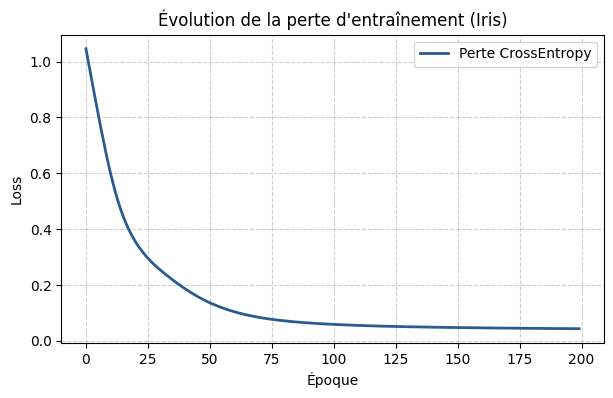

In [45]:
# 1. Courbe d'évolution de la perte
plt.figure(figsize=(7, 4))
plt.plot(losses, label="Perte CrossEntropy", color="#2b5c8f", lw=2)
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la perte d'entraînement (Iris)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


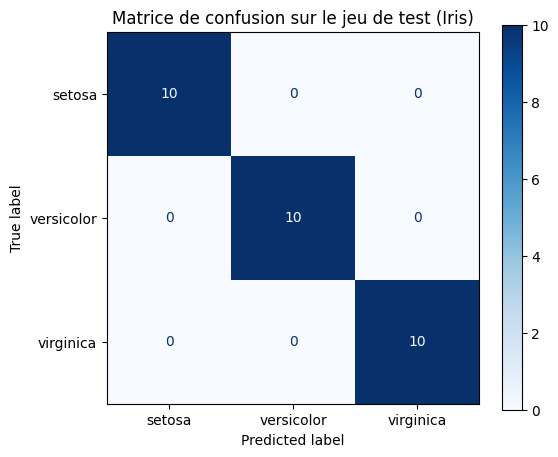

In [46]:
# 2. Matrice de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test.numpy(), predictions.numpy())
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title("Matrice de confusion sur le jeu de test (Iris)")
plt.show()

In [47]:
# 3. Comparaison avec un modèle sans couche cachée : nn.Linear(4, 3)
model_linear = nn.Linear(4, 3)
optimizer_linear = torch.optim.Adam(model_linear.parameters(), lr=0.01)

model_linear.train()
for epoch in range(200):
    optimizer_linear.zero_grad()
    loss_lin = criterion(model_linear(X_train), y_train)
    loss_lin.backward()
    optimizer_linear.step()

model_linear.eval()
with torch.no_grad():
    pred_lin = model_linear(X_test).argmax(dim=1)
    acc_lin = (pred_lin == y_test).float().mean()

print(f"Accuracy modèle avec couche cachée MLP : {accuracy.item():.1%}")
print(f"Accuracy modèle linéaire pur nn.Linear(4, 3) : {acc_lin.item():.1%}")

Accuracy modèle avec couche cachée MLP : 100.0%
Accuracy modèle linéaire pur nn.Linear(4, 3) : 90.0%


In [48]:
# 4. Prédire l'espèce d'une nouvelle fleur [5.1, 3.5, 1.4, 0.2]
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur_norm = scaler.transform(nouvelle_fleur)
nouvelle_fleur_tensor = torch.tensor(nouvelle_fleur_norm, dtype=torch.float32)

model.eval()
with torch.no_grad():
    scores = model(nouvelle_fleur_tensor)
    probabilites = torch.softmax(scores, dim=1)
    classe_predite = scores.argmax(dim=1).item()

espece = iris.target_names[classe_predite]
print(f"Fleur mesurée : [5.1, 3.5, 1.4, 0.2]")
print(f"Espèce prédite : {espece.upper()}")
print("Probabilités par classe :")
for nom, prob in zip(iris.target_names, probabilites[0]):
    print(f"  - {nom:10s} : {prob.item():.2%}")

Fleur mesurée : [5.1, 3.5, 1.4, 0.2]
Espèce prédite : SETOSA
Probabilités par classe :
  - setosa     : 99.99%
  - versicolor : 0.01%
  - virginica  : 0.00%


###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [49]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé :
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

In [50]:
# 1. Entraînement du modèle MLP sur 5 époques
epochs = 5
mlp_loss_history = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    mlp_loss_history.append(epoch_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte moyenne : {epoch_loss:.4f}")

Époque 1/5 | Perte moyenne : 0.3542
Époque 2/5 | Perte moyenne : 0.1669
Époque 3/5 | Perte moyenne : 0.1166
Époque 4/5 | Perte moyenne : 0.0888
Époque 5/5 | Perte moyenne : 0.0698


In [51]:
# 2. Évaluation sur le jeu de test et calcul des métriques
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)
        all_preds.extend(predicted_classes.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_targets, all_preds)
precision = precision_score(all_targets, all_preds, average="macro")
recall = recall_score(all_targets, all_preds, average="macro")
f1 = f1_score(all_targets, all_preds, average="macro")

print("=" * 45)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("=" * 45)
print("\nRapport de classification détaillé :\n")
print(classification_report(all_targets, all_preds, digits=4))

Accuracy  : 0.9758 (97.58%)
Precision : 0.9757
Recall    : 0.9755
F1-Score  : 0.9756

Rapport de classification détaillé :

              precision    recall  f1-score   support

           0     0.9778    0.9888    0.9833       980
           1     0.9894    0.9912    0.9903      1135
           2     0.9805    0.9748    0.9776      1032
           3     0.9715    0.9792    0.9753      1010
           4     0.9695    0.9725    0.9710       982
           5     0.9786    0.9720    0.9753       892
           6     0.9831    0.9729    0.9780       958
           7     0.9710    0.9776    0.9743      1028
           8     0.9660    0.9641    0.9651       974
           9     0.9691    0.9623    0.9657      1009

    accuracy                         0.9758     10000
   macro avg     0.9757    0.9755    0.9756     10000
weighted avg     0.9758    0.9758    0.9758     10000



<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


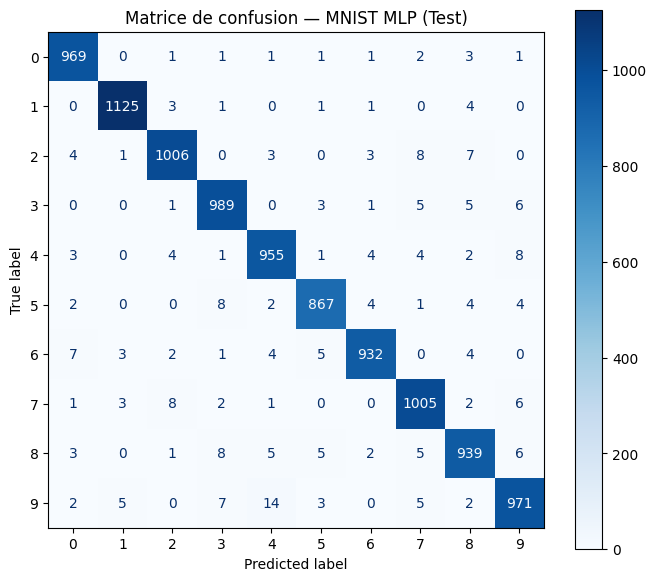

In [52]:
# 3. Matrice de confusion pour MNIST MLP
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_mnist = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mnist, display_labels=list(range(10)))
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Matrice de confusion — MNIST MLP (Test)")
plt.show()

<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


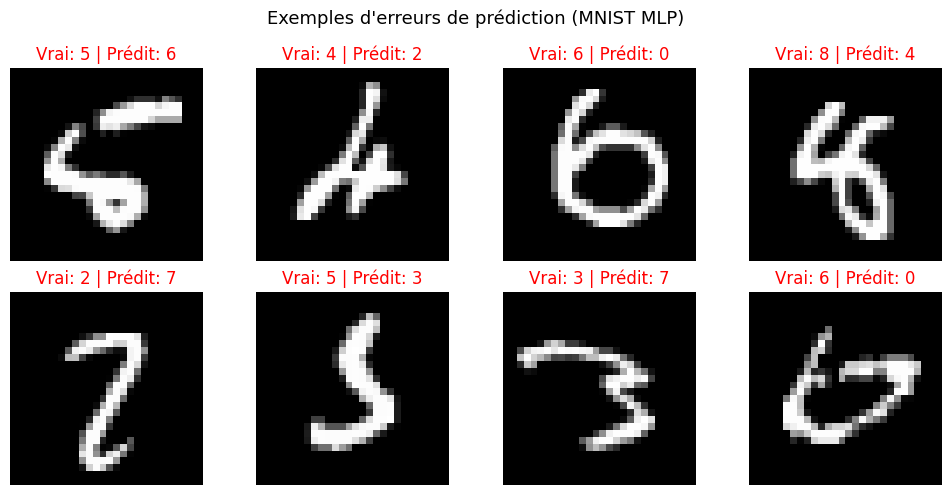

In [53]:
# 4. Affichage de quelques images mal classées
import numpy as np

all_preds_arr = np.array(all_preds)
all_targets_arr = np.array(all_targets)
erreurs_idx = np.where(all_preds_arr != all_targets_arr)[0]

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes = axes.flatten()

for i, idx in enumerate(erreurs_idx[:8]):
    image_tensor, vraie_classe = test_dataset[idx]
    classe_pred = all_preds_arr[idx]

    axes[i].imshow(image_tensor.squeeze().numpy(), cmap="gray")
    axes[i].set_title(f"Vrai: {vraie_classe} | Prédit: {classe_pred}", color="red")
    axes[i].axis("off")

plt.suptitle("Exemples d'erreurs de prédiction (MNIST MLP)", fontsize=13)
plt.tight_layout()
plt.show()

In [54]:
# 5. Sauvegarder et recharger le modèle MLP
save_path = "mnist_mlp_model.pth"
torch.save(model.state_dict(), save_path)
print(f"Modèle sauvegardé avec succès dans '{save_path}'")

# Recharger dans une nouvelle instance
model_reloaded = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
model_reloaded.load_state_dict(torch.load(save_path))
model_reloaded.eval()

# Vérification sur un batch de test
sample_images, sample_labels = next(iter(test_loader))
with torch.no_grad():
    preds_orig = model(sample_images).argmax(dim=1)
    preds_reloaded = model_reloaded(sample_images).argmax(dim=1)

assert torch.equal(preds_orig, preds_reloaded), "Erreur: Les prédictions ne correspondent pas !"
print("Vérification réussie : le modèle rechargé produit exactement les mêmes prédictions.")

Modèle sauvegardé avec succès dans 'mnist_mlp_model.pth'
Vérification réussie : le modèle rechargé produit exactement les mêmes prédictions.


### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [55]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

### 💡 Réponses aux questions (Chargement MNIST CNN)

1. **Que représentent les quatre dimensions du tenseur `images` ?**
   - `images.shape` = `[64, 1, 28, 28]` :
     - **Dimension 0 (64) :** Taille du mini-lot (*batch size*), nombre d'images traitées en parallèle.
     - **Dimension 1 (1) :** Nombre de canaux (*channels*), 1 car il s'agit d'images en niveaux de gris (noir et blanc).
     - **Dimension 2 (28) :** Hauteur de l'image en pixels (*height*).
     - **Dimension 3 (28) :** Largeur de l'image en pixels (*width*).

2. **Pourquoi mélanger les données d’entraînement avec `shuffle=True` ?**
   - Évite d'introduire des biais d'ordre dans la descente de gradient stochastique (ex: des chiffres regroupés par paquets de 0, puis de 1, etc.).
   - Assure que chaque mini-lot est un échantillon représentatif et indépendant (i.i.d.) de l'ensemble du dataset.
   - Favorise une convergence plus rapide, stable et évite le surapprentissage lié à la séquence de présentation des données.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


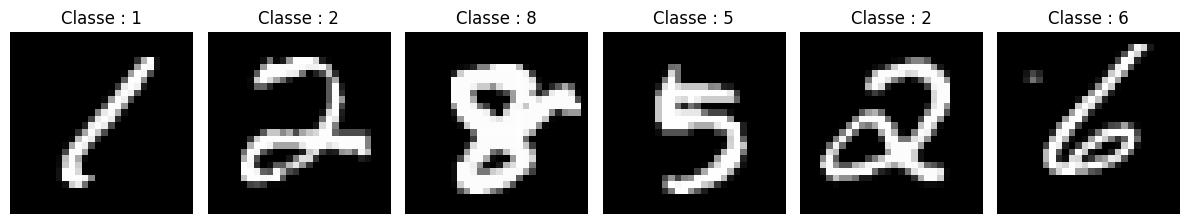

In [56]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

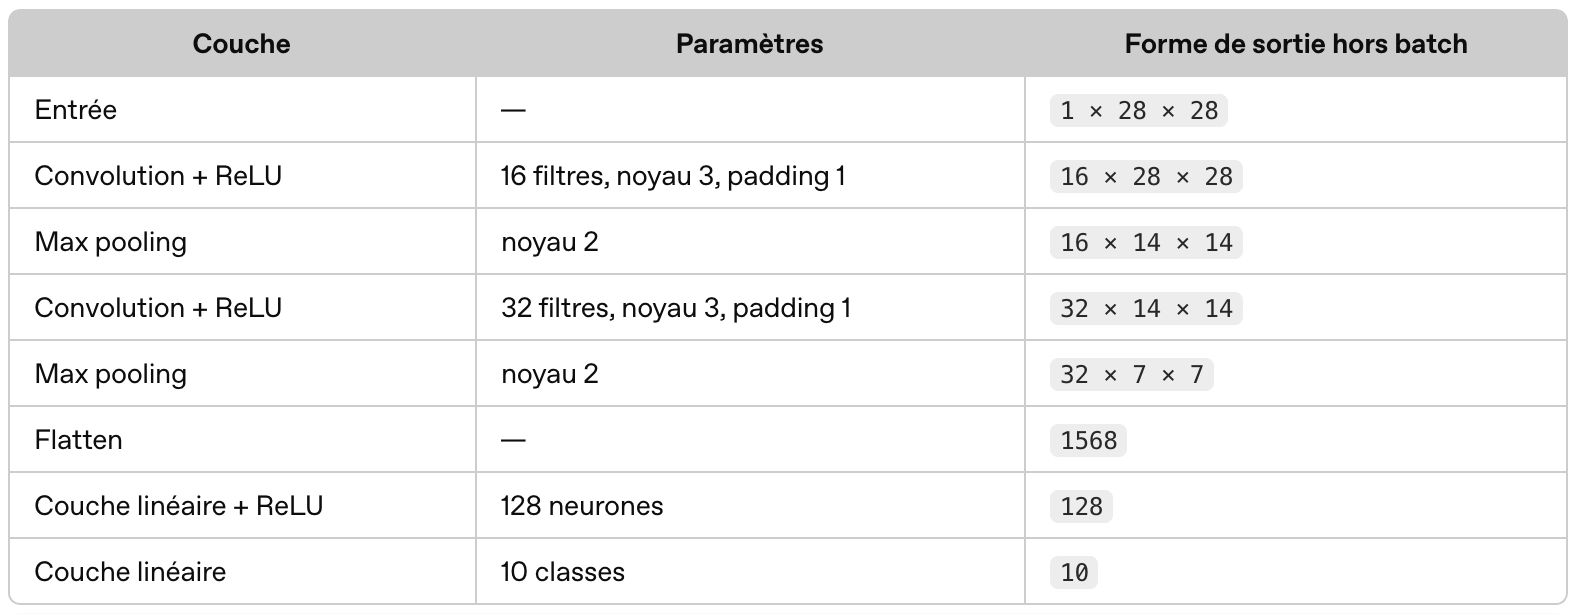

In [57]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

### 💡 Explication géométrique : Pourquoi la première couche linéaire reçoit-elle $32 \times 7 \times 7$ valeurs ?

Suivons la taille spatiale et le nombre de canaux à travers le réseau :

1. **Entrée :** Tenseur $[B, 1, 28, 28]$.
2. **Conv2d(1, 16, kernel=3, padding=1) :**
   $$\text{Taille} = \frac{28 - 3 + 2(1)}{1} + 1 = 28 \implies [B, 16, 28, 28]$$
3. **MaxPool2d(kernel=2) :**
   $$\text{Taille} = \frac{28}{2} = 14 \implies [B, 16, 14, 14]$$
4. **Conv2d(16, 32, kernel=3, padding=1) :**
   $$\text{Taille} = \frac{14 - 3 + 2(1)}{1} + 1 = 14 \implies [B, 32, 14, 14]$$
5. **MaxPool2d(kernel=2) :**
   $$\text{Taille} = \frac{14}{2} = 7 \implies [B, 32, 7, 7]$$
6. **Flatten() :**
   $$32 \times 7 \times 7 = 1568 \text{ valeurs par image du lot.}$$

La première couche linéaire dense doit donc obligatoirement avoir `in_features = 32 * 7 * 7 = 1568` pour recevoir l'ensemble des caractéristiques extraites.

**4. Entraîner le réseau**

In [58]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1680
Époque 2/3 | Perte : 0.0482
Époque 3/3 | Perte : 0.0351


**5. Évaluer sur le jeu de test**

In [59]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.88%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

<string>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


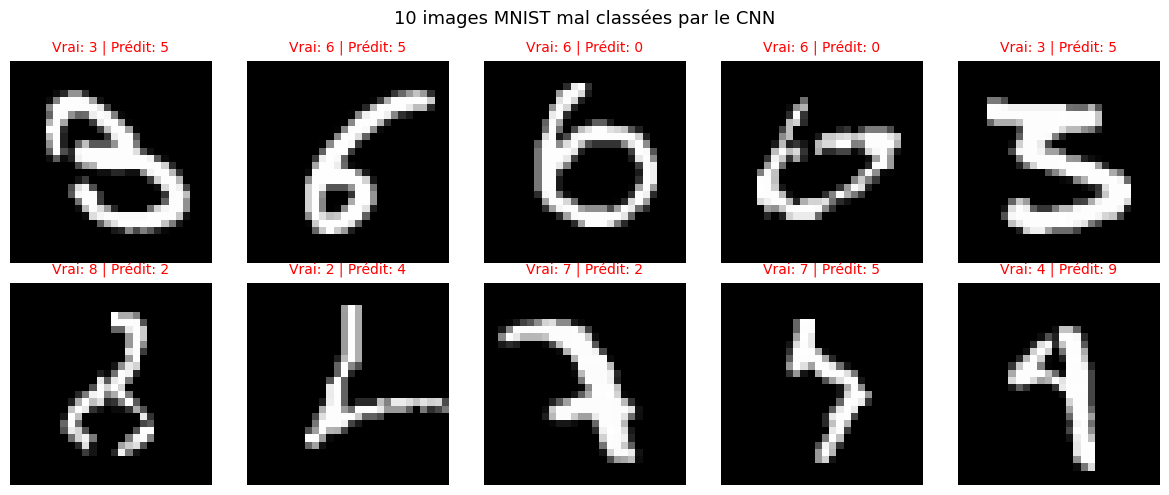

In [60]:
# 1. Afficher 10 images mal classées, avec leur vraie classe et la prédiction
model.eval()
cnn_misclassified_images = []
cnn_true_labels = []
cnn_pred_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        preds = model(images_dev).argmax(dim=1).cpu()
        
        erreurs = (preds != labels)
        if erreurs.any():
            for img, true_l, pred_l in zip(images[erreurs], labels[erreurs], preds[erreurs]):
                # Dénormaliser l'image pour un bon affichage
                img_denorm = img[0] * 0.3081 + 0.1307
                cnn_misclassified_images.append(img_denorm)
                cnn_true_labels.append(true_l.item())
                cnn_pred_labels.append(pred_l.item())
                if len(cnn_misclassified_images) >= 10:
                    break
        if len(cnn_misclassified_images) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for i in range(10):
    axes[i].imshow(cnn_misclassified_images[i].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(f"Vrai: {cnn_true_labels[i]} | Prédit: {cnn_pred_labels[i]}", color="red", fontsize=10)
    axes[i].axis("off")

plt.suptitle("10 images MNIST mal classées par le CNN", fontsize=13)
plt.tight_layout()
plt.show()

In [61]:
# 2. Modèle CNN avec couche Dropout avant la dernière couche linéaire
class MNISTClassifierWithDropout(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),  # Régularisation par Dropout
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_dropout = MNISTClassifierWithDropout(dropout_rate=0.5).to(device)
print(model_dropout)

# Entraînement rapide sur 1 époque pour valider le fonctionnement
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.001)
model_dropout.train()
for imgs, lbls in train_loader:
    imgs, lbls = imgs.to(device), lbls.to(device)
    opt_dropout.zero_grad()
    loss_d = criterion(model_dropout(imgs), lbls)
    loss_d.backward()
    opt_dropout.step()

model_dropout.eval()
corr_d = 0
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        corr_d += (model_dropout(imgs).argmax(dim=1) == lbls).sum().item()

print(f"Accuracy du modèle avec Dropout après 1 époque : {corr_d / len(test_dataset):.2%}")

MNISTClassifierWithDropout(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Accuracy du modèle avec Dropout après 1 époque : 98.16%


In [62]:
# 3. Sauvegarder les paramètres dans 'mnist_cnn.pth' et tester le rechargement
save_cnn_path = "mnist_cnn.pth"
torch.save(model.state_dict(), save_cnn_path)
print(f"Paramètres du CNN sauvegardés avec succès dans '{save_cnn_path}'")

# Rechargement et vérification
reloaded_cnn = MNISTClassifier().to(device)
reloaded_cnn.load_state_dict(torch.load(save_cnn_path))
reloaded_cnn.eval()

# Vérification sur un batch de test
sample_imgs, sample_lbls = next(iter(test_loader))
sample_imgs = sample_imgs.to(device)
with torch.no_grad():
    out_orig = model(sample_imgs).argmax(dim=1)
    out_reloaded = reloaded_cnn(sample_imgs).argmax(dim=1)

assert torch.equal(out_orig, out_reloaded), "Erreur: Incohérence lors du rechargement !"
print("Vérification réussie : le modèle CNN rechargé est identique.")

Paramètres du CNN sauvegardés avec succès dans 'mnist_cnn.pth'
Vérification réussie : le modèle CNN rechargé est identique.
